In [3]:
import pandas as pd
from tqdm import tqdm
import itertools
import numpy as np

In [2]:
from EvaluateDisambiguation import evaluate_methods, plot_results


In [4]:
test_file = pd.read_excel("../DisambiguationAnnoation/name_test_Liu_Mingrong_final.xlsx")

# Add title -> paper id mapping
author_departs = pd.read_csv("../DisambiguationData/Authorship_ValidChinese.csv")
title_pid = dict(zip(author_departs['title'], author_departs['paper id']))
test_file['title1_pid'] = test_file['title1'].map(title_pid)
test_file['title2_pid'] = test_file['title2'].map(title_pid)

# Map Chinese name to English (Pinyin)
unique_english_names_full = pd.read_csv("../DisambiguationData/Pinyin/CNKI_uniqueChineseNames_withPinyin.csv")
name_en = dict(zip(unique_english_names_full['fullname'], unique_english_names_full['fullname_english']))
test_file['name_en'] = test_file['name'].map(name_en)

In [5]:
# ## Step 2. Evaluate each method

# Chinese dataset results
chinese_files = {
    "Our method": "../DisambiguationData/name_disambiguation_output/4_author_doi_citation.csv",
    "Sinatra": "../DisambiguationData/name_disambiguation_output/5_sinatra_results.csv",
    "Waqas": "../DisambiguationData/name_disambiguation_output/3_author_doi_title.csv"
}
chinese_results = evaluate_methods(test_file, chinese_files, "name")

# English dataset results
english_files = {
    "Our method": "../DisambiguationData/English_names_disambiguation/4_author_doi_citation.csv",
    "Sinatra": "../DisambiguationData/English_names_disambiguation/5_author_doi_Sinatra.csv",
    "Waqas": "../DisambiguationData/English_names_disambiguation/3_author_doi_title.csv"
}
english_results = evaluate_methods(test_file, english_files, "name_en")


/Users/shemingrong/Chinese_author_names/Version4_upload/DisambiguationDataCodes/DisambiguationCodes/EvaluateDisambiguation.py:31: PerformanceWarning: indexing past lexsort depth may impact performance.
  idx1 = df.loc[title1_pids[i], names[i]]['author_index']
/Users/shemingrong/Chinese_author_names/Version4_upload/DisambiguationDataCodes/DisambiguationCodes/EvaluateDisambiguation.py:32: PerformanceWarning: indexing past lexsort depth may impact performance.
  idx2 = df.loc[title2_pids[i], names[i]]['author_index']
/Users/shemingrong/Chinese_author_names/Version4_upload/DisambiguationDataCodes/DisambiguationCodes/EvaluateDisambiguation.py:31: PerformanceWarning: indexing past lexsort depth may impact performance.
  idx1 = df.loc[title1_pids[i], names[i]]['author_index']
/Users/shemingrong/Chinese_author_names/Version4_upload/DisambiguationDataCodes/DisambiguationCodes/EvaluateDisambiguation.py:32: PerformanceWarning: indexing past lexsort depth may impact performance.
  idx2 = df.loc[ti

/Users/shemingrong/Chinese_author_names/Version4_upload/DisambiguationDataCodes/DisambiguationCodes/EvaluateDisambiguation.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


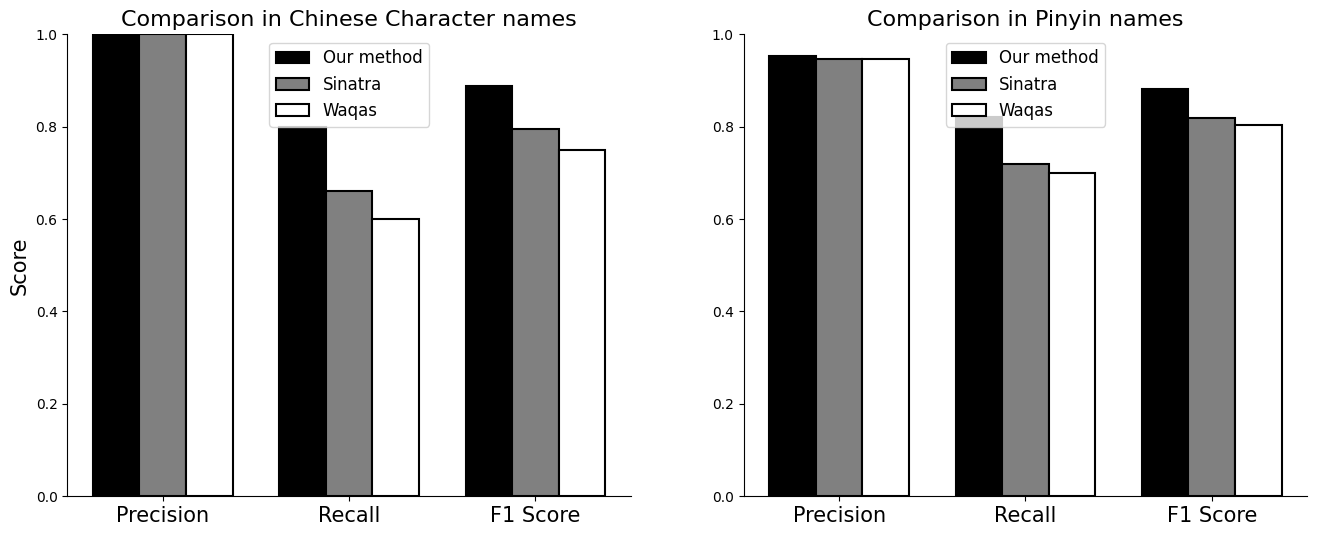

In [9]:
plot_results(chinese_results, english_results, output_path="../Comparison_Sinatra_Waqas.pdf")

In [ ]:
import gzip
import shutil
from pathlib import Path

# 目标目录
folder = Path("../DisambiguationData")

for file in folder.rglob("*.csv"):  # 递归找所有 .csv
    gz_path = file.with_suffix(file.suffix + ".gz")
    with open(file, 'rb') as f_in, gzip.open(gz_path, 'wb') as f_out:
        shutil.copyfileobj(f_in, f_out)
    print(f"压缩完成: {gz_path}")

压缩完成: ../DisambiguationData/CNKI_dataset_updated_withValidNames_withPID_withLanguage.csv.gz
压缩完成: ../DisambiguationData/Authorship_ValidChinese.csv.gz
压缩完成: ../DisambiguationData/Paper_Translation.csv.gz
压缩完成: ../DisambiguationData/AbstractSimilarity.csv.gz
压缩完成: ../DisambiguationData/CNKI_dataset_updated_withValidNames_withPID_FullChinese.csv.gz
压缩完成: ../DisambiguationData/Authorship_English.csv.gz
压缩完成: ../DisambiguationData/CNKI_dataset_updated_withValidNames.csv.gz
压缩完成: ../DisambiguationData/Pinyin/CNKI_uniqueChineseNames.csv.gz
压缩完成: ../DisambiguationData/Pinyin/character_dictionary_withEng.csv.gz
压缩完成: ../DisambiguationData/Pinyin/CNKI_uniqueChineseNames_withPinyin.csv.gz
压缩完成: ../DisambiguationData/Pinyin/family_py.csv.gz
压缩完成: ../DisambiguationData/GET_citations/PUBLICATIONS.csv.gz
压缩完成: ../DisambiguationData/GET_citations/Processed_Citations.csv.gz
压缩完成: ../DisambiguationData/GET_citations/CITATION_METADATA/3,5.csv.gz
压缩完成: ../DisambiguationData/GET_citations/CITATION_METADAT